# Lesson 6 — How good is FORM? Verification and the method decision

Every number of lessons 4 and 5 rests on FORM. Lesson 2 showed that the
product of a lognormal model uncertainty and a Gumbel load curves the
failure surface and makes FORM optimistic by a few hundredths. The
calibration limit state contains exactly such products — on both sides:
$z\,\Theta_R R$ and $\Theta_E\,\Theta_Q Q$. This lesson quantifies the
effect over the whole model and shows what it does to the calibrated
factors.

Tools (all in `codecal.reliability`):

* **SORM** — Breitung's curvature correction, about 70 % extra cost;
* **importance sampling** around the FORM design point — a few thousand
  samples per situation give β to ±0.01, independent of any
  linearisation.

In [1]:
import os
import sys
import time

import numpy as np
import pandas as pd

try:
    import codecal as cc
except ImportError:
    sys.path.insert(0, os.path.abspath('..'))
    import codecal as cc
from codecal import plots
from codecal.plots import Figure

FIG = 'figures'
os.makedirs(FIG, exist_ok=True)
pd.set_option('display.width', 120)


def save(fig, name):
    """Save a figure next to the lesson and show it (inline in Jupyter/Spyder)."""
    fig.savefig(os.path.join(FIG, name), dpi=150, bbox_inches='tight')
    try:
        from IPython.display import display
        display(fig)
    except ImportError:            # plain python: the PNG in figures/ is the output
        pass


model = cc.ahg_model()
situations = model.design_situations()

## 1. FORM, SORM and importance sampling for every design situation

For each of the 810 situations: FORM (as in the sweep), SORM at the same
design point, and importance sampling with 20 000 samples.

In [2]:
t0 = time.time()
rows = []
for s in situations:
    z = s.design_parameter(cc.START_VALUES, '8.12')
    ls = s.limit_state(z)
    res = cc.form(ls)
    b_sorm, kappa = cc.sorm(ls, res)
    isr = cc.importance_sampling(ls, res, n=20_000, seed=len(rows))
    rows.append({'mode': s.mode.name, 'load': s.load.name, 'a_G': s.a_G, 'a_Q': s.a_Q,
                 'beta_form': res.beta, 'beta_sorm': b_sorm, 'beta_is': isr.beta, 'se_is': isr.se_beta,
                 'kappa_min': kappa.min(), 'dominant': s.variable_names[int(np.argmax(np.abs(res.alpha)))]})
ver = pd.DataFrame(rows)
print(f"{len(ver)} situations verified in {time.time() - t0:.0f} s")
ver['form-is'] = ver.beta_form - ver.beta_is
ver['sorm-is'] = ver.beta_sorm - ver.beta_is
print(ver[['form-is', 'sorm-is', 'se_is']].describe().round(4).to_string())

810 situations verified in 4 s
        form-is   sorm-is     se_is
count  810.0000  810.0000  810.0000
mean     0.0414    0.0007    0.0039
std      0.0189    0.0042    0.0002
min     -0.0057   -0.0135    0.0034
25%      0.0299   -0.0021    0.0037
50%      0.0437    0.0008    0.0039
75%      0.0555    0.0034    0.0040
max      0.0838    0.0130    0.0070


FORM overestimates β by about 0.04 on average, up to 0.09; SORM agrees
with the sampling estimate to within its standard error. The bias is not
uniform — it depends on which variable dominates:

         form-is              sorm-is             
            mean    max count    mean    max count
dominant                                          
Q          0.015  0.050   165   0.001  0.010   165
R          0.053  0.074    96   0.001  0.013    96
Θ_E        0.063  0.084    24  -0.002  0.009    24
Θ_Q        0.044  0.071   246   0.001  0.012   246
Θ_R        0.049  0.080   279   0.000  0.012   279

         form-is  sorm-is
load                     
imposed    0.025    0.001
snow       0.048    0.001
wind       0.051    0.000


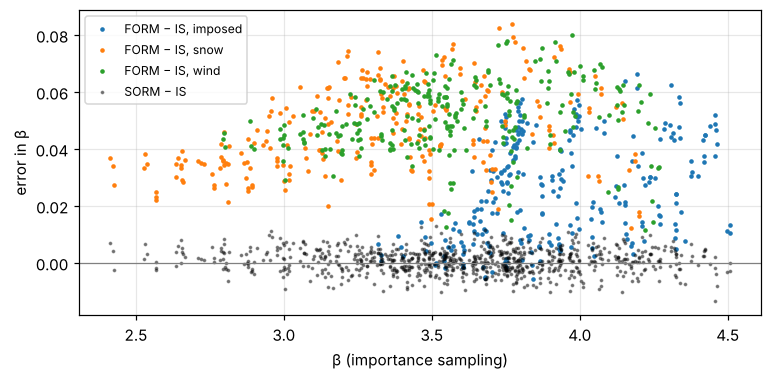

In [3]:
print(ver.groupby('dominant')[['form-is', 'sorm-is']].agg(['mean', 'max', 'count']).round(3).to_string())
print()
print(ver.groupby('load')[['form-is', 'sorm-is']].mean().round(3).to_string())

fig = Figure(figsize=(8, 3.6))
ax = fig.subplots()
for load, grp in ver.groupby('load'):
    ax.plot(grp.beta_is, grp['form-is'], '.', ms=4, label=f'FORM − IS, {load}')
ax.plot(ver.beta_is, ver['sorm-is'], 'k.', ms=3, alpha=0.4, label='SORM − IS')
ax.axhline(0, color='grey', lw=0.8)
ax.set_xlabel('β (importance sampling)')
ax.set_ylabel('error in β')
ax.grid(alpha=0.3)
ax.legend(fontsize=8)
save(fig, 'lesson06_form_error.png')

Situations dominated by a *lognormal* variable — the model uncertainties
$\Theta_E$, $\Theta_R$, $\Theta_Q$ and the strengths — carry the largest
first-order error (0.05–0.06 in β); those dominated by the Gumbel load
itself the smallest. Per load: wind and snow ≈ 0.05, imposed ≈ 0.025.
In β terms the AHG study is systematically optimistic by ≈ 0.04; the
next section shows what that is worth in partial factors.

## 2. Calibrating with SORM instead of FORM

`method='sorm'` applies the correction inside every objective evaluation.

two calibrations in 43 s

FORM:
calibrated gamma_G, gamma_Q  (β_t = 3.8)
  gamma_G            1.215
  gamma_Q            1.750
  weighted-mean β  3.741 → 3.809
  objective        1.366e-01   (16 evaluations)

SORM:
calibrated gamma_G, gamma_Q  (β_t = 3.8)
  gamma_G            1.228
  gamma_Q            1.761
  weighted-mean β  3.705 → 3.808
  objective        1.406e-01   (17 evaluations)


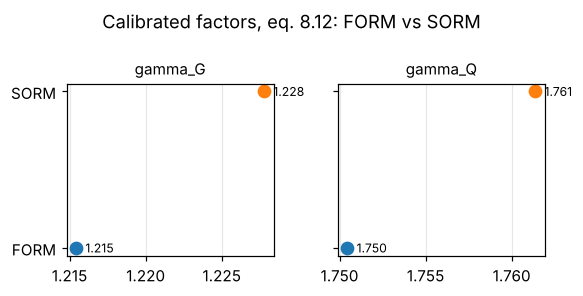

In [4]:
t0 = time.time()
cal_form = cc.calibrate(model, ('gamma_G', 'gamma_Q'), equation='8.12', method='form', verbose=False)
cal_sorm = cc.calibrate(model, ('gamma_G', 'gamma_Q'), equation='8.12', method='sorm', verbose=False)
print(f"two calibrations in {time.time() - t0:.0f} s\n")
print("FORM:", cal_form, sep='\n')
print("\nSORM:", cal_sorm, sep='\n')
save(plots.plot_gamma_comparison({'FORM': cal_form, 'SORM': cal_sorm},
                                 title='Calibrated factors, eq. 8.12: FORM vs SORM'),
     'lesson06_gamma_form_vs_sorm.png')

The status-quo weighted mean drops from 3.74 (FORM) to 3.70 (SORM), and
the calibrated factors rise by about 0.01–0.015 each. Which method a
code committee adopts is a decision — the target β itself was set with
FORM in mind — but it has to be a conscious one, and the size of the
effect should be known. That is what this lesson is for.

## 3. Sampling as the final arbiter

When in doubt, importance sampling with more samples settles the
question for any single situation. Steel bending under wind, the grid
point closest to the situation of lesson 3:

In [5]:
s = next(x for x in situations if x.mode.name == 'Steel bending' and x.load.name == 'wind'
         and abs(x.a_G - 0.8) < 1e-9 and abs(x.a_Q - 0.5) < 0.03)
z = s.design_parameter(cc.START_VALUES, '8.12')
ls = s.limit_state(z)
res = cc.form(ls)
for n in (2_000, 20_000, 200_000):
    isr = cc.importance_sampling(ls, res, n=n, seed=7)
    print(f"importance sampling, n = {n:7,d}: β = {isr.beta:.4f} ± {isr.se_beta:.4f}")
print(f"FORM {res.beta:.4f}, SORM {cc.sorm(ls, res)[0]:.4f}")
mc = cc.monte_carlo(ls, n=2_000_000, seed=7)
print(f"crude Monte Carlo, n = 2,000,000: β = {mc.beta:.4f} ± {mc.se_beta:.4f}")

importance sampling, n =   2,000: β = 3.4948 ± 0.0122
importance sampling, n =  20,000: β = 3.4849 ± 0.0040
importance sampling, n = 200,000: β = 3.4755 ± 0.0012
FORM 3.5196, SORM 3.4776


crude Monte Carlo, n = 2,000,000: β = 3.4808 ± 0.0120


## Exercises

1. Which single CoV of the model would you reduce to make FORM accurate
   enough? Try halving the CoV of the wind model uncertainty and rerun
   section 1 for the wind situations.
2. The sensitivity factor of the *dominant* variable is often above 0.7
   for wind. Compare with the fixed α = 0.7 of EN 1990 Annex C: in which
   situations would the design-value format be conservative, in which not?
3. Repeat section 2 for eq. 8.13 with ξ free. Does SORM change ξ?